stateid
Jammu & Kashmir              1613
Himachal Pradesh             1388
Punjab                       2124
Chandigarh                   1026
Uttarakhand                  1358
Haryana                      1898
Delhi                        1319
Rajasthan                    2244
Uttar Pradesh                4567
Bihar                        3520
Arunachal Pradesh            1215
Nagaland                     1316
Manipur                      1369
Mizoram                      1246
Tripura                      1195
Meghalaya                     969
Assam                        2366
West Bengal                  3933
Jharkhand                    2464
Odisha                       2917
Chhattisgarh                 2055
Madhya Pradesh               2914
Gujarat                      2341
Daman & Diu                   991
Dadra & Nagar Haveli         1090
Maharashtra                  3973
Andhra Pradesh               2679
Karnataka                    2420
Goa                          1427
Laksha

C:\Users\shrey\AppData\Local\Temp\ipykernel_16132\2629200280.py:74: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  ncp["sex"] = ncp["sex"].replace({"male": 1, "Male": 1, "M": 1, "female": 2, "Female": 2, "F": 2})
C:\Users\shrey\AppData\Local\Temp\ipykernel_16132\2629200280.py:277: RuntimeWarning: divide by zero encountered in scalar divide
  y_all = e["gsva_cr"].sum() * 1e7 / e["workers"].sum()
C:\Users\shrey\AppData\Local\Temp\ipykernel_16132\2629200280.py:286: RuntimeWarning: invalid value encountered in scalar multiply
  dY = r["added"] * v / 1e7                                          # Rs crore


 sex age_band   n     F  F_lo  F_hi     U  U_lo  U_hi     N  N_lo  N_hi  working  working_lo  working_hi  seeking  seeking_lo  seeking_hi  any_pension  any_pension_lo  any_pension_hi
   1    60-64 203 0.382 0.309 0.456 0.074 0.038 0.111 0.405 0.331 0.478    0.789       0.732       0.846    0.018         0.0       0.035        0.284           0.217           0.351
   1    65-69 159 0.273 0.194 0.352 0.102 0.052 0.152 0.431 0.346 0.516    0.708       0.633       0.782    0.004         0.0       0.012        0.557           0.472           0.642
   1    70-74 100 0.197 0.113 0.282 0.110 0.049 0.170 0.307 0.205 0.408    0.504       0.398       0.609    0.040         0.0       0.089        0.573           0.470           0.675
   1    75-79  72 0.099 0.017 0.181 0.109 0.032 0.185 0.220 0.118 0.322    0.314       0.192       0.436    0.000         0.0       0.000        0.770           0.661           0.879
   1      80+  67 0.050 0.001 0.098 0.162 0.061 0.264 0.163 0.070 0.256    0.213     

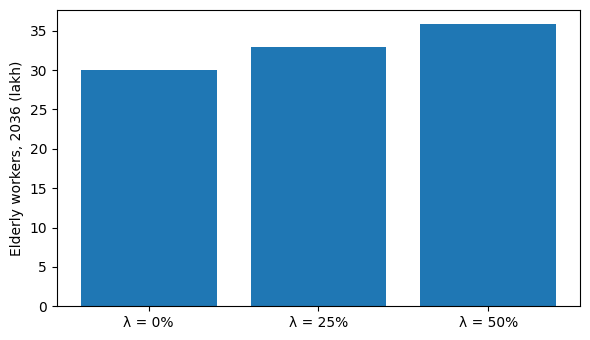

In [27]:
# %% 1. Imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# %% 2. Parameters
lasi_path = "3_LASI_W1_Individual_data.dta"

ncp_path = "Pop.csv"          # sheets: pop (total), male, female; rows = age groups, columns = years
ncp_sheets = {1: "Male", 2: "Female"}      # sex code -> sheet name (use your actual sheet names)
ncp_unit = 1                               # 1 if persons, 1000 if thousands, 1e5 if lakh (check totals in Cell 4)

es_path = "es.csv"  # Economic Survey GSVA table: rows = industries, columns = fiscal years
es_year = "2023-24"                        # fiscal year used for GSVA per worker
es_unit_to_crore = 1 / 100                 # file in Rs lakh -> crore (CHECK units)
workers_es = {                             # sector workers in es_year, persons (PLFS or other source; fill in)
    "agriculture": np.nan,
    "industry": np.nan,
    "services": np.nan,
}

per_to_month = {1: 26.0, 2: 52 / 12, 3: 1.0, 4: 1 / 12}   # 1 Day, 2 Week, 3 Month, 4 Year (confirmed)
full_time_hours_week = 48

jobs_fy24, jobs_2036 = 2.2e7, 2.8e7        # Vision: confirm against full document
lfpr_base, lfpr_2036 = 0.63, 0.74
base_year, target_year = 2024, 2036

fit_def = "core"                           # broad | core | strict
lambdas = [0.0, 0.25, 0.50]
drop_proxy = False                         # decide after seeing rproxy counts

age_bands = ["60-64", "65-69", "70-74", "75-79", "80+"]
age_start = dict(zip(age_bands, [60, 65, 70, 75, 80]))
sectors = ["agriculture", "industry", "services"]

# %% 3. Load LASI (only the columns needed)
use_cols = (
    ["prim_key", "hhid", "stateid", "residence", "mpce_quintile",
     "stateindividualweight", "rproxy",
     "dm003", "dm005",
     "we004", "we005", "we018", "we020", "we020_unit", "we023", "we026", "we201", "we412",
     "sw202a", "sw202b", "sw202c", "sw202d", "sw202e",
     "ht303", "ht306", "ht307", "ht309", "ht310"]
    + [f"ht{n}" for n in range(401, 414)]
)
lasi = pd.read_stata(lasi_path, columns=use_cols)          # keeps value labels
print(lasi["stateid"].value_counts().sort_index().head(40))

lasi = lasi[lasi["stateid"].astype(str).str.contains("Odisha", case=False)].copy()
# if the labels carry no state name: lasi = lasi[lasi["stateid"].astype(str).str.startswith("21")].copy()

code_cols = (["residence", "rproxy", "dm003", "we004", "we005", "we201", "we020_unit", "we023",
              "sw202a", "sw202b", "sw202c", "sw202d", "sw202e", "we412",
              "ht303", "ht306", "ht307", "ht309", "ht310"]
             + [f"ht{n}" for n in range(401, 414)])
for c in code_cols:                                        # '3 Month' -> 3
    if str(lasi[c].dtype) == "category" or lasi[c].dtype == object:
        lasi[c] = pd.to_numeric(lasi[c].astype(str).str.extract(r"^\s*(\d+)")[0], errors="coerce")
for c in ["dm005", "we018", "we020", "we026", "stateindividualweight"]:
    lasi[c] = pd.to_numeric(lasi[c], errors="coerce")

lasi = lasi.rename(columns={"stateindividualweight": "w", "we020_unit": "we020_per"})
lasi = lasi[lasi["w"].notna()]
lasi["psu"] = lasi["hhid"].astype(str)      # stopgap: no PSU in the file, CIs will be too narrow
lasi["strata"] = lasi["residence"]
print(lasi.shape)

# %% 4a. NCP population (already long: age, year, sex, pop)
ncp = pd.read_csv(ncp_path)
print(ncp.columns.tolist(), ncp["sex"].unique(), ncp["age"].unique()[:5])

ncp["age_start"] = pd.to_numeric(ncp["age"].astype(str).str.extract(r"(\d+)")[0], errors="coerce")
ncp["sex"] = ncp["sex"].replace({"male": 1, "Male": 1, "M": 1, "female": 2, "Female": 2, "F": 2})
ncp["year"] = pd.to_numeric(ncp["year"], errors="coerce")
ncp["pop"] = pd.to_numeric(ncp["pop"], errors="coerce") * ncp_unit
ncp = ncp[ncp["age_start"].notna() & ncp["year"].notna() & ncp["sex"].isin([1, 2])]
ncp["age_start"] = ncp["age_start"].clip(upper=80)         # 80+ band
ncp = ncp.groupby(["year", "sex", "age_start"], as_index=False)["pop"].sum()

print(sorted(ncp["age_start"].unique()))                   # expect 0, 5, ..., 80
print(ncp.groupby(["year", "sex"])["pop"].sum().unstack().loc[[2021, 2026, 2031, 2036]])  # 2036 total about 45 million

# %% 4b. Economic Survey GSVA by sector
g = pd.read_csv(es_path, index_col=0)
g.columns = [" ".join(str(c).split()) for c in g.columns]  # tidy split / padded headers
g.index = [" ".join(str(i).split()) for i in g.index]
print(g.columns.tolist())
print(g.index.tolist())                                     # check the row names


def gsva_row(name):
    row = g.loc[[i for i in g.index if i.lower().startswith(name.lower())][0]]
    col = [c for c in g.columns if c.startswith(es_year)][0]
    return pd.to_numeric(row[col], errors="coerce") * es_unit_to_crore


agri = gsva_row("Agriculture, Forestry")
mining = gsva_row("Mining")
secondary = gsva_row("Secondary")
tertiary = gsva_row("Tertiary")             # CHECK: services total row; rename if it is called something else

es = pd.DataFrame({
    "sector": sectors,
    "gsva_cr": [agri, mining + secondary, tertiary],
    "workers": [workers_es[s] for s in sectors],
})
print(es)
total = gsva_row("TOTAL GSVA")
print("sum of sectors:", es["gsva_cr"].sum().round(0), "| file total:", round(total, 0))
assert abs(es["gsva_cr"].sum() - total) / total < 0.01, "sectors do not add up to the total"
print("workers filled in:", es["workers"].notna().all())

# %% 5. Code checks: run once, paste the output
for c in ["dm003", "residence", "rproxy", "we004", "we005", "we201", "we020_per",
          "we023", "ht303", "ht401", "ht407", "sw202a", "we412"]:
    print(c); print(lasi[c].value_counts(dropna=False).sort_index().head(15)); print()
print(lasi.groupby("we020_per")["we020"].median())          # should rise day -> year
print("hhid sample:", lasi["hhid"].head(10).tolist())
print("age range:", lasi["dm005"].min(), lasi["dm005"].max())

# %% 6. Construct variables
df = lasi.copy()
if drop_proxy:
    df = df[df["rproxy"] != 1]                # CHECK: proxy coding

adl = [f"ht{i}" for i in range(401, 407)]
mob = ["ht303", "ht306", "ht307", "ht309", "ht310"]
iadl = [f"ht{i}" for i in range(407, 414)]
for c in adl + mob + iadl:                    # CHECK: 1 = yes (difficulty), 2 = no
    df[c] = df[c].where(df[c].isin([1, 2]))

df["sex"] = df["dm003"]                       # CHECK: 1 male, 2 female
df["age_band"] = pd.cut(df["dm005"], [59, 64, 69, 74, 79, 120], labels=age_bands)

fit_items = {"broad": adl, "core": adl + mob, "strict": adl + mob + iadl}
df["working"] = ((df["we004"] == 1) | (df["we005"] == 1)).astype(int)    # CHECK codes
df["seeking"] = ((df["we201"] == 1) | (df["we005"] == 2)).astype(int)    # CHECK codes
for name, cols in fit_items.items():
    complete = df[cols].notna().all(axis=1)
    fit = ~df[cols].eq(1).any(axis=1)
    wk = df["working"] == 1
    df[f"F_{name}"] = (fit & wk).astype(float).where(complete)           # fit, working
    df[f"U_{name}"] = (fit & ~wk).astype(float).where(complete)          # fit, not working
    df[f"N_{name}"] = ((~fit) & wk).astype(float).where(complete)        # working, not fit

sw_cols = ["sw202a", "sw202b", "sw202c", "sw202d", "sw202e"]             # CHECK: 1 = yes
df["social_pension"] = (df[sw_cols] == 1).any(axis=1).astype(int)
df["work_pension"] = (df["we412"] == 1).astype(int)
df["any_pension"] = ((df["social_pension"] == 1) | (df["work_pension"] == 1)).astype(int)

print("Odisha 60+ (unweighted n):", (df["dm005"] >= 60).sum())

# %% 7. Survey-weighted shares by age band and sex
def wshare(d, y, dom):
    """Weighted share of y in domain dom, Taylor-linearised 95% CI (strata, PSU)."""
    ok = d[y].notna()
    wd = d["w"] * (dom & ok)
    sw = wd.sum()
    if sw == 0:
        return np.nan, np.nan, np.nan
    yy = d[y].fillna(0)
    p = (wd * yy).sum() / sw
    z = (wd * (yy - p) / sw).groupby([d["strata"], d["psu"]]).sum()
    var = 0.0
    for _, g_ in z.groupby(level=0):
        if len(g_) > 1:
            var += len(g_) / (len(g_) - 1) * ((g_ - g_.mean()) ** 2).sum()
    se = np.sqrt(var)
    return p, max(0, p - 1.96 * se), min(1, p + 1.96 * se)


def age_sex_table(d, fit):
    rows = []
    for sex in sorted(d["sex"].dropna().unique()):
        for ab in age_bands:
            dom = (d["age_band"] == ab) & (d["sex"] == sex)
            r = {"sex": sex, "age_band": ab, "n": int(dom.sum())}
            for label, var in [("F", f"F_{fit}"), ("U", f"U_{fit}"), ("N", f"N_{fit}"),
                               ("working", "working"), ("seeking", "seeking"),
                               ("any_pension", "any_pension")]:
                r[label], r[label + "_lo"], r[label + "_hi"] = wshare(d, var, dom)
            rows.append(r)
    return pd.DataFrame(rows)


ind = age_sex_table(df, fit_def)
print(ind.round(3).to_string(index=False))

# %% 8. Productivity inputs: sector mix m, hours factor h, relative productivity phi
wk = df[df["working"] == 1].copy()
wk["sector"] = np.where(wk["we023"] == 1, "agriculture",
                np.where(wk["we023"].isin([2, 3, 4, 5, 6]), "industry", "services"))  # CHECK we023 codes
monthly = wk["we020"] * wk["we020_per"].map(per_to_month)
wk["hourly"] = monthly / (wk["we018"] * 52 / 12)
lo, hi = wk["hourly"].quantile([0.01, 0.99])
wk["hourly"] = wk["hourly"].clip(lo, hi)
wk["h"] = (wk["we018"] * wk["we026"] / (full_time_hours_week * 12)).clip(0, 1)


def wmean(x, w):
    ok = x.notna() & w.notna()
    return np.average(x[ok], weights=w[ok]) if ok.any() else np.nan


w60 = wk[wk["dm005"] >= 60]
w4559 = wk[(wk["dm005"] >= 45) & (wk["dm005"] <= 59)]
m = (w60.groupby("sector")["w"].sum() / w60["w"].sum()).reindex(sectors).fillna(0)
h = wmean(w60["h"], w60["w"])
phi_j = {}
for j in sectors:
    a = wmean(w60.loc[w60["sector"] == j, "hourly"], w60.loc[w60["sector"] == j, "w"])
    b = wmean(w4559.loc[w4559["sector"] == j, "hourly"], w4559.loc[w4559["sector"] == j, "w"])
    phi_j[j] = a / b
ok_j = [j for j in sectors if not np.isnan(phi_j[j])]
phi = sum(m[j] * phi_j[j] for j in ok_j) / sum(m[j] for j in ok_j)
print("sector mix:", m.round(3).to_dict(), "| h =", round(h, 3), "| phi =", round(phi, 3))

# %% 9. Population functions (NCP)
def ncp_at(year):
    years = np.array(sorted(ncp["year"].unique()))
    if year in years:
        return ncp[ncp["year"] == year].set_index(["sex", "age_start"])["pop"]
    y0, y1 = years[years < year].max(), years[years > year].min()
    a = ncp[ncp["year"] == y0].set_index(["sex", "age_start"])["pop"]
    b = ncp[ncp["year"] == y1].set_index(["sex", "age_start"])["pop"]
    return a + (b - a) * (year - y0) / (y1 - y0)


def bands(pop):
    p = pop.reset_index()
    rows = [{"sex": s, "age_band": ab,
             "pop": p[(p["sex"] == s) & (p["age_start"] == age_start[ab])]["pop"].sum()}
            for s in sorted(p["sex"].unique()) for ab in age_bands]
    return pd.DataFrame(rows)


def pop_between(pop, lo, hi=None):
    p = pop.reset_index()
    sel = p["age_start"] >= lo
    if hi is not None:
        sel &= p["age_start"] <= hi
    return p.loc[sel, "pop"].sum()


pop_T, pop_B, pop_26 = ncp_at(target_year), ncp_at(base_year), ncp_at(2026)

# %% 10. Employment model
def workers(ind_table, pop60, suffix=""):
    x = ind_table.merge(pop60, on=["sex", "age_band"])
    L0 = (x["pop"] * (x["F" + suffix] + x["N" + suffix])).sum()    # baseline elderly workers
    U = (x["pop"] * x["U" + suffix]).sum()                         # untapped pool
    return L0, U


L0, U = workers(ind, bands(pop_T))
L0_base, _ = workers(ind, bands(pop_B))
scen = pd.DataFrame({"lambda": lambdas})
scen["added"] = scen["lambda"] * U
scen["elderly_workers"] = L0 + scen["added"]
print(f"Baseline elderly workers {target_year}: {L0:,.0f} | untapped pool: {U:,.0f}")

# %% 11. Comparison with the Vision
pop15 = pop_between(pop_T, 15)
loss_15_59 = pop_between(pop_T, 15, 55) - pop_between(pop_26, 15, 55)    # 2026 -> 2036
scen["gain_vs_base_year"] = scen["elderly_workers"] - L0_base
scen["share_of_vision_jobs_increase"] = scen["gain_vs_base_year"] / (jobs_2036 - jobs_fy24)
scen["elderly_pp_of_15plus"] = 100 * scen["elderly_workers"] / pop15
scen["vision_pp_rise_needed"] = 100 * (lfpr_2036 - lfpr_base)
scen["change_pop_15_59_2026_T"] = loss_15_59
scen["added_vs_15_59_change"] = scen["added"] / abs(loss_15_59)
print(scen.round(3).to_string(index=False))

# %% 12. Indicative output (GSVA per worker: low / central / high)
e = es.set_index("sector")
y_sector = {j: e.loc[j, "gsva_cr"] * 1e7 / e.loc[j, "workers"] for j in sectors}   # Rs per worker
y_all = e["gsva_cr"].sum() * 1e7 / e["workers"].sum()
ybar = sum(m[j] * y_sector[j] for j in sectors)
per_worker = {"low": h * phi * y_sector["agriculture"], "central": h * phi * ybar, "high": y_all}
gsva_total_cr = e["gsva_cr"].sum()
pop_total = pop_between(pop_T, 0)

rows = []
for _, r in scen.iterrows():
    for case, v in per_worker.items():
        dY = r["added"] * v / 1e7                                          # Rs crore
        rows.append({"lambda": r["lambda"], "case": case, "added_output_cr": dY,
                     "pct_of_latest_gsva": 100 * dY / gsva_total_cr,
                     "rs_per_capita": dY * 1e7 / pop_total})
output = pd.DataFrame(rows)
print(output.pivot_table(index="lambda", columns="case", values="pct_of_latest_gsva").round(3))

# %% 13. Sensitivity: fitness definition x CI bound x lambda
rows = []
for fit in ["broad", "core", "strict"]:
    t = age_sex_table(df, fit)
    for suffix, label in [("", "point"), ("_lo", "lower CI"), ("_hi", "upper CI")]:
        L0_s, U_s = workers(t, bands(pop_T), suffix)
        for lam in lambdas:
            rows.append({"fit": fit, "bound": label, "lambda": lam,
                         "elderly_workers": L0_s + lam * U_s})
sens = pd.DataFrame(rows)
print(sens.pivot_table(index=["fit", "bound"], columns="lambda", values="elderly_workers").round(0))

# %% 14. Chart and save
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar([f"λ = {l:.0%}" for l in scen["lambda"]], scen["elderly_workers"] / 1e5)
ax.set_ylabel(f"Elderly workers, {target_year} (lakh)")
plt.tight_layout()
plt.savefig("elderly_workers_by_scenario.png", dpi=150)

ind.to_csv("indicators.csv", index=False)
scen.to_csv("scenarios_vision.csv", index=False)
output.to_csv("output_range.csv", index=False)
sens.to_csv("sensitivity.csv", index=False)

In [2]:
import numpy as np
import pandas as pd


In [13]:
df = pd.read_stata("3_LASI_W1_Individual_data.dta")
ncp = pd.read_csv("Pop.csv")
df.shape

(72250, 2650)

In [9]:
df["ht401"].unique()

['2 No', '1 Yes', NaN]
Categories (2, object): ['1 Yes' < '2 No']

In [28]:
# %% 5. Diagnostics: run once and paste the output
pd.set_option("display.width", 200)

# 5a. Sample and coding checks (labels were converted to codes in Cell 3)
print("Odisha rows:", len(lasi), "| 60+:", (lasi["dm005"] >= 60).sum())
print("weight: min/median/max", lasi["w"].min(), lasi["w"].median(), lasi["w"].max())
print("age range:", lasi["dm005"].min(), lasi["dm005"].max())
print("hhid sample:", lasi["hhid"].head(10).tolist())
print("households:", lasi["hhid"].nunique(), "| persons per household (mean):",
      round(len(lasi) / lasi["hhid"].nunique(), 2))
print()

for c in ["dm003", "residence", "rproxy", "we004", "we005", "we201",
          "we020_per", "we023", "we412", "sw202a", "sw202b"]:
    print(c)
    print(lasi[c].value_counts(dropna=False).sort_index().head(15).to_string())
    print()

# 5b. Difficulty items (1 = yes, 2 = no is assumed): share with difficulty among 60+
items = ["ht303", "ht306", "ht307", "ht309", "ht310"] + [f"ht{i}" for i in range(401, 414)]
old_ = lasi[lasi["dm005"] >= 60]
chk = pd.DataFrame({
    "n_1": [(old_[c] == 1).sum() for c in items],
    "n_2": [(old_[c] == 2).sum() for c in items],
    "n_other_or_missing": [(~old_[c].isin([1, 2])).sum() for c in items],
}, index=items)
chk["pct_1_of_valid"] = (100 * chk["n_1"] / (chk["n_1"] + chk["n_2"])).round(1)
print(chk.to_string())
print()

# 5c. Earnings: median amount by period (should rise day -> year) and implied hourly wage
wk_ = lasi[(lasi["we004"] == 1) | (lasi["we005"] == 1)]
print(wk_.groupby("we020_per")["we020"].describe()[["count", "25%", "50%", "75%"]].to_string())
print("workers with earnings missing:", wk_["we020"].isna().sum(), "of", len(wk_))
print("workers with hours missing:", wk_["we018"].isna().sum(), "| with months missing:", wk_["we026"].isna().sum())
print()

# 5d. Unweighted cell counts for 60+ by sex and age band: workers, fit, not fit
tmp = lasi[lasi["dm005"] >= 60].copy()
tmp["age_band"] = pd.cut(tmp["dm005"], [59, 64, 69, 74, 79, 120], labels=age_bands)
tmp["working"] = ((tmp["we004"] == 1) | (tmp["we005"] == 1)).astype(int)
cells = tmp.groupby(["dm003", "age_band"], observed=True).agg(
    n=("working", "size"),
    n_working=("working", "sum"),
    w_sum=("w", "sum"),
    w_max_share=("w", lambda s: round(s.max() / s.sum(), 3)),   # largest single weight in the cell
)
print(cells.to_string())
print()

# 5e. Population check
for y in [2021, 2024, 2026, 2031, 2036]:
    p = ncp_at(y)
    print(y, "| total:", f"{pop_between(p, 0):,.0f}",
          "| 15-59:", f"{pop_between(p, 15, 55):,.0f}",
          "| 60+:", f"{pop_between(p, 60):,.0f}",
          "| 60+ share:", round(100 * pop_between(p, 60) / pop_between(p, 0), 1))
print("change in 15-59, 2026 -> target:", f"{pop_between(ncp_at(target_year), 15, 55) - pop_between(ncp_at(2026), 15, 55):,.0f}")
print()

# 5f. GSVA table check
print(es)
print("workers filled in:", es["workers"].notna().all())

Odisha rows: 2917 | 60+: 1237
weight: min/median/max 639.8436 3168.2722 25033.463
age range: 27 105
hhid sample: ['121130600220200', '121130600220200', '121130600300300', '121130600300300', '121130600320100', '121130600320100', '121130600360100', '121130600360100', '121130600360200', '121130600360200']
households: 1635 | persons per household (mean): 1.78

dm003
dm003
1    1255
2    1662

residence
residence
1    2435
2     482

rproxy
rproxy
0    2892
1      25

we004
we004
1.0    1424
2.0     491
NaN    1002

we005
we005
1.0      40
2.0       2
3.0     242
4.0     117
5.0      90
NaN    2426

we201
we201
1.0      50
2.0    1862
NaN    1005

we020_per
we020_per
1.0     523
2.0       5
3.0     239
4.0     694
NaN    1456

we023
we023
1.0     979
2.0      14
3.0      26
4.0       4
5.0      12
6.0      87
7.0     105
8.0      20
9.0      31
10.0      4
11.0      5
12.0      3
13.0     18
14.0      9
15.0      6

we412
we412
1.0      62
2.0      37
3.0    1381
NaN    1437

sw202a
sw202a
